# Fourier-mode decay of Newton-generated KdV waves

Generate periodic traveling-wave profiles with `KdVNewton`, inspect how their Fourier coefficients decay with mode number, and evolve one profile with the KdV time solver. These are two different views: spectral decay is coefficient size **across mode number**; the time plot shows how each mode's magnitude changes **during evolution**. For an exact traveling wave, modal magnitudes are constant in time while their phases change.

This version uses the `camera` package: the grid and the time step come from a `Camera(L, N, dt)` object, and the solvers are `camera.spectralCamera.KdVNewton` and `camera.pdeCamera.KdV`. Helper functions come from `solvers.help`.
The last section compares the Fourier spectra and the maximum profile error against the cnoidal solution for several values of $N$.

**Amplitude convention.** In `camera.spectralCamera` the target amplitude is the **crest elevation above the mean**, $\phi(0)=\text{mean}+\text{amp}$ (not the first-harmonic amplitude used by the older `solvers.spectral`). The profiles therefore differ from the old notebook for the same numbers.

In [20]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import ellipj, ellipk, ellipe
from scipy.optimize import brentq

root = next((path for path in (Path.cwd(), *Path.cwd().parents) if (path / "camera").is_dir()), None)
if root is None:
    raise RuntimeError("Run this notebook from within the project so its camera package can be found.")
sys.path.insert(0, str(root))

from camera.camera_file import Camera
from camera.spectralCamera import KdVNewton
from camera.pdeCamera import KdV
from camera.help import *

## Generate the traveling-wave profiles

`KdVNewton.phi_hat` uses coefficients normalized by `N`, so the physical profile is `get_physical(phi_hat) = irfft(N * phi_hat)`. The real-FFT index is the nonnegative mode number, with wavenumber `2 pi mode / P`.
The camera window equals the period, $L=P$, so each wave fills the window exactly.

In [21]:
P = 2 * np.pi
N = 128
dt = 1e-3
mean = 0.0
target_amplitudes = [0.1, 0.4, 2, 4]

cam = Camera(P, N, dt)

waves = []
profiles = []
for target_amp in target_amplitudes:
    wave = KdVNewton(P=P, target_amp=target_amp, mean=mean, camera=cam)
    wave.solve_w_continuation(n_steps=20)
    waves.append(wave)
    profiles.append(wave.get_physical(wave.phi_hat))

modes = np.arange(N // 2 + 1)
wavenumbers = 2 * np.pi * modes / P
coefficient_magnitudes = np.array([np.abs(wave.phi_hat) for wave in waves])

print(f"Generated {len(waves)} profiles with {N} grid points on a period P={P:.3g}.")

Generated 4 profiles with 128 grid points on a period P=6.28.


## Spectral decay across modes

The first panel shows coefficient magnitude against mode number; the second uses a logarithmic magnitude axis to make the tail visible. The dashed line is a least-squares exponential-tail fit on the selected modes for the largest-amplitude wave. Change `fit_modes` to inspect another range; the fitted slope is descriptive, not a universal decay rate.

Fitted log-amplitude slope over modes 4-24: -0.9105


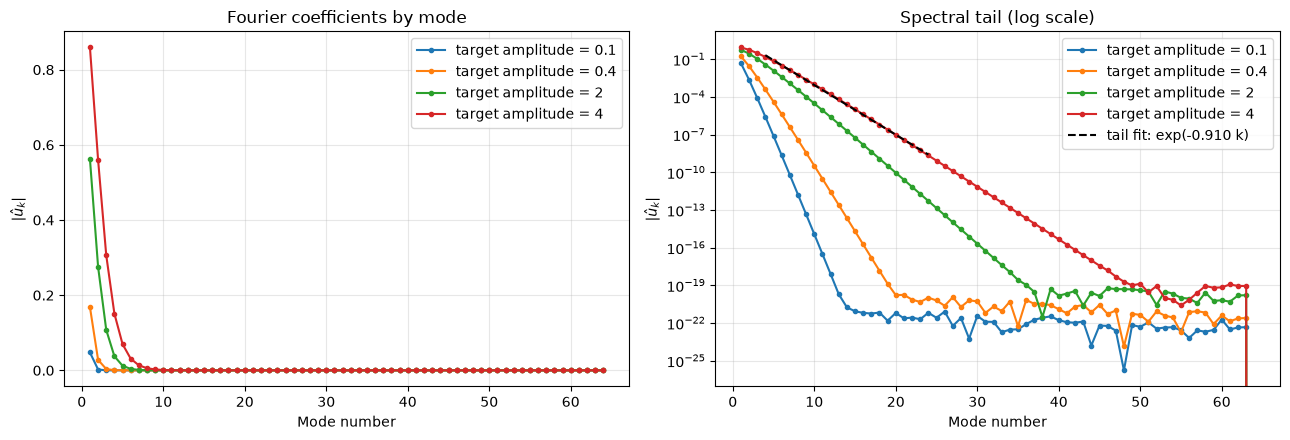

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for target_amp, magnitudes in zip(target_amplitudes, coefficient_magnitudes):
    label = f"target amplitude = {target_amp:g}"
    axes[0].plot(modes[1:], magnitudes[1:], marker=".", label=label)
    axes[1].semilogy(modes[1:], magnitudes[1:], marker=".", label=label)

axes[0].set(title="Fourier coefficients by mode", xlabel="Mode number", ylabel=r"$|\hat{u}_k|$")
axes[1].set(title="Spectral tail (log scale)", xlabel="Mode number", ylabel=r"$|\hat{u}_k|$")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()

fit_modes = (4, min(25, N // 2 + 1))
fit_indices = np.arange(*fit_modes)
fit_values = coefficient_magnitudes[-1, fit_indices]
valid = np.isfinite(fit_values) & (fit_values > 0)
if np.count_nonzero(valid) >= 2:
    slope, intercept = np.polyfit(fit_indices[valid], np.log(fit_values[valid]), 1)
    axes[1].semilogy(
        fit_indices[valid], np.exp(intercept + slope * fit_indices[valid]),
        "k--", label=f"tail fit: exp({slope:.3f} k)"
    )
    axes[1].legend()
    print(f"Fitted log-amplitude slope over modes {fit_modes[0]}-{fit_modes[1] - 1}: {slope:.4f}")
else:
    print("Not enough positive coefficients in the selected range to fit a spectral tail.")

plt.tight_layout()
plt.show()

## Modal magnitudes during KdV evolution

Evolve the largest generated profile and plot several nonzero Fourier-mode magnitudes over time. A steadily translating wave should keep these magnitudes nearly constant; changes indicate numerical error or a departure from a steadily translating profile.
The solver step is `cam.dt`; frames are saved every `save_every` steps.

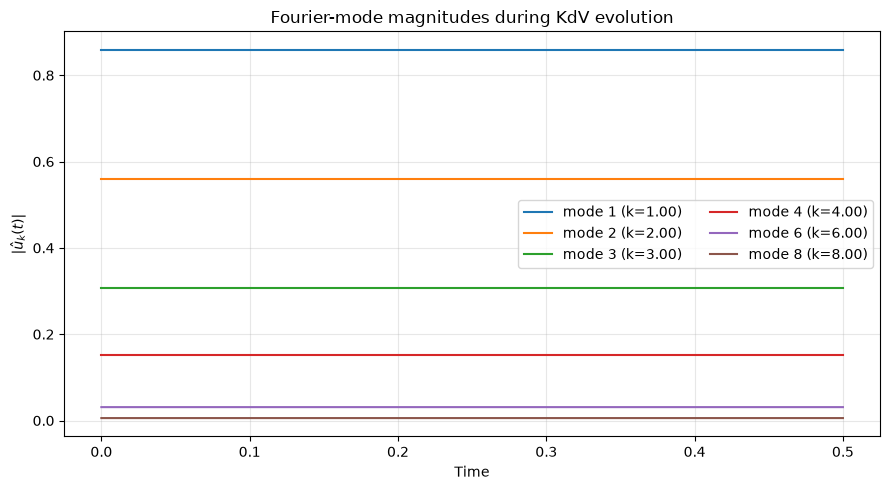

Mode 1: relative magnitude change over T=0.5: +7.896e-07
Mode 2: relative magnitude change over T=0.5: +3.012e-07
Mode 3: relative magnitude change over T=0.5: -5.435e-06
Mode 4: relative magnitude change over T=0.5: -6.022e-06
Mode 6: relative magnitude change over T=0.5: +5.717e-06
Mode 8: relative magnitude change over T=0.5: +1.115e-04


In [23]:
T = 0.5
save_every = 10
solver = KdV(camera=cam, T=T, u0=profiles[-1], save_every=save_every)
times, solution = solver.splitStep()

solution_hat = np.fft.rfft(solution, axis=1) / N
modal_magnitudes = np.abs(solution_hat)
selected_modes = [1, 2, 3, 4, 6, 8]

fig, ax = plt.subplots(figsize=(9, 5))
for mode in selected_modes:
    ax.plot(times, modal_magnitudes[:, mode], label=f"mode {mode} (k={wavenumbers[mode]:.2f})")
ax.set(title="Fourier-mode magnitudes during KdV evolution", xlabel="Time", ylabel=r"$|\hat{u}_k(t)|$")
ax.grid(True, alpha=0.3)
ax.legend(ncol=2)
plt.tight_layout()
plt.show()

relative_change = (modal_magnitudes[-1, selected_modes] - modal_magnitudes[0, selected_modes]) / modal_magnitudes[0, selected_modes]
for mode, change in zip(selected_modes, relative_change):
    print(f"Mode {mode}: relative magnitude change over T={times[-1]:.3g}: {change:+.3e}")

## Fourier modes and maximum profile error for different $N$

For each pair (amplitude, $N$) the Newton wave is compared with the cnoidal solution that has the same period, mean and crest elevation.
The cnoidal wave is evaluated on the camera grid. `phi_hat_mid` is the Newton spectrum shifted by half a period, so the crest sits at $x=0$ on the symmetric camera grid, as for the cnoidal wave.

`cn_reference` uses the same formulas as `kdv_cnoidal` but solves for $m$ with a tight tolerance in `brentq`. With the default `xtol` the reference itself limits the error near $m\to1$ (about $7\cdot10^{-13}$ at $m=0.999$).

In [24]:
def cn_reference(P, crest, mean, x):
    '''Cnoidal solution of (1/6)phi'' + (1-c)phi + phi^2/2 = B with phi(0)=crest, mean(phi)=mean.'''
    def params(m):
        K, E  = ellipk(m), ellipe(m)
        kappa = 2*K/P
        b     = 2*m*kappa**2
        q     = (E - (1-m)*K)/(m*K)
        return kappa, mean - b*q, b
    def residual(m):
        _, a, b = params(m)
        return a + b - crest
    m = brentq(residual, 1e-9, 1 - 1e-9, xtol=1e-16, rtol=4*np.finfo(float).eps)
    kappa, a, b = params(m)
    c = 1 + a + (2/3)*kappa**2*(2*m - 1)
    return a + b*ellipj(kappa*x, m)[1]**2, c, m

N_list = [2**5, 2**6, 2**7, 2**8]
amps_N = [0.1, 0.4, 1.5, 4]            # amplitudes (crest elevation) for the error panel
amp_spec = 4                           # amplitude whose spectra are shown for each N

rows, spectra = [], {}
for amp in target_amplitudes:
    for n in N_list:
        cam_n = Camera(P, n, dt)
        try:
            w = KdVNewton(P=P, target_amp=amp, mean=mean, camera=cam_n)
            w.solve_w_continuation(n_steps=20)
            phi_N = w.get_physical(w.phi_hat_mid)
            phi_cn, c_cn, m_cn = cn_reference(P, amp, mean, cam_n.x)
            err = np.max(np.abs(phi_N - phi_cn))
            if amp == amp_spec:
                spectra[n] = np.abs(w.phi_hat)
            rows.append((amp, n, m_cn, err, abs(w.c - c_cn), np.abs(w.phi_hat[n//2 - 1])))
        except Exception as e:
            rows.append((amp, n, np.nan, np.nan, np.nan, np.nan))
df = pd.DataFrame(rows, columns=["amp", "N", "m", "max_err", "c_err", "tail_coeff"])
print(df.to_string(index=False, float_format=lambda v: f"{v:.2e}"))

     amp   N        m  max_err    c_err  tail_coeff
1.00e-01  32 3.17e-01 1.39e-16 0.00e+00    1.04e-21
1.00e-01  64 3.17e-01 1.53e-16 0.00e+00    4.67e-23
1.00e-01 128 3.17e-01 1.53e-16 0.00e+00    4.62e-23
1.00e-01 256 3.17e-01 1.53e-16 0.00e+00    4.81e-24
4.00e-01  32 7.40e-01 7.22e-16 0.00e+00    2.01e-15
4.00e-01  64 7.40e-01 2.22e-16 1.11e-16    2.89e-21
4.00e-01 128 7.40e-01 3.33e-16 0.00e+00    2.46e-22
4.00e-01 256 7.40e-01 3.33e-16 0.00e+00    6.86e-23
2.00e+00  32 9.90e-01 8.22e-08 1.01e-08    5.52e-08
2.00e+00  64 9.90e-01 2.89e-15 6.66e-16    5.54e-17
2.00e+00 128 9.90e-01 3.11e-15 4.44e-16    1.62e-20
2.00e+00 256 9.90e-01 3.11e-15 6.66e-16    4.96e-21
4.00e+00  32 9.99e-01 2.49e-05 3.64e-06    1.01e-05
4.00e+00  64 9.99e-01 6.46e-12 8.56e-13    2.67e-12
4.00e+00 128 9.99e-01 3.64e-14 9.33e-15    8.82e-20
4.00e+00 256 9.99e-01 3.64e-14 8.88e-15    3.57e-21


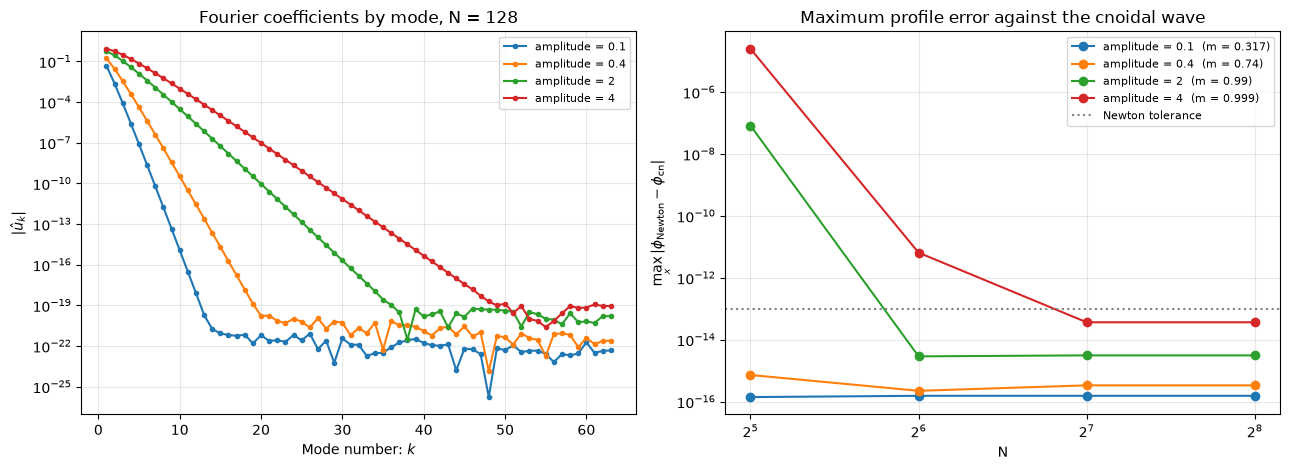

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

N_fixed = 2**7
assert N == N_fixed, "coefficient_magnitudes was computed with a different N"

# one colour per amplitude, shared by both panels
colors = {amp: f"C{i}" for i, amp in enumerate(target_amplitudes)}

# left: Fourier-mode magnitudes for all amplitudes at fixed N
for amp, mags in zip(target_amplitudes, coefficient_magnitudes):
    keep = (modes >= 1) & (mags > 0)          # the Nyquist coefficient is exactly zero
    axes[0].semilogy(modes[keep], mags[keep], marker=".", color=colors[amp],
                     label=f"amplitude = {amp:g}")
axes[0].set(title=f"Fourier coefficients by mode, N = {N_fixed}",
            xlabel=r"Mode number: $k$", ylabel=r"$|\hat{u}_k|$")

# right: maximum profile error against N, one curve per amplitude
for amp in target_amplitudes:
    d = df[df.amp == amp]
    label = (f"amplitude = {amp:g}  (m = {d.m.dropna().iloc[0]:.3g})"
             if d.m.notna().any() else f"amplitude = {amp:g}")
    axes[1].semilogy(d.N, d.max_err + 1e-18, "o-", color=colors.get(amp), label=label)
axes[1].set_xscale("log", base=2)
axes[1].axhline(1e-13, color="gray", ls=":", label="Newton tolerance")
axes[1].set(title="Maximum profile error against the cnoidal wave",
            xlabel="N", ylabel=r"$\max_x|\phi_{\rm Newton}-\phi_{\rm cn}|$")

for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()